# Preference Learning and Reward Modelling for Language Models


## 1. Background: Why Reward Models for Language?

In games like chess or Go, reward signals are straightforward — win or lose. Language is fundamentally different: there are countless valid ways to say the same thing, and no hand-crafted rule set can reliably distinguish helpful from harmful outputs.

A naive approach might penalize outputs containing specific offensive words, but this breaks down quickly — insulting outputs can avoid such words, and non-insulting outputs may legitimately reference them.

Christiano et al. (2017) addressed a similar problem in robotics: how do you reward a backflip without writing an explicit definition? Their solution was to show human evaluators pairs of video clips and ask which looked more like a backflip, then train a reward model from these comparisons. Ouyang et al. (2022) applied this idea to language — the result is **Reinforcement Learning from Human Feedback (RLHF)**.

Instead of hand-crafted rewards, RLHF learns from *pairwise preferences*: given two outputs, which is better? This provides a natural, scalable way to encode complex human preferences.

Key references:
- [Deep RL from Human Feedback — Christiano et al. 2017](https://arxiv.org/abs/1706.03741)
- [InstructGPT — Ouyang et al. 2022](https://arxiv.org/abs/2203.02155)
- [AlphaZero — Silver et al. 2017](https://arxiv.org/abs/1712.01815)


## 2. The Bradley–Terry Model

The Bradley–Terry model is a probabilistic model for learning preferences from pairwise comparisons. Given a question $x$ and two responses $y_i$, $y_j$, each with a latent score $s(x, y)$, the probability that $y_i$ is preferred is:

$$
P(y_i \succ y_j | x) = \frac{\exp(s(x,y_i))}{\exp(s(x,y_i)) + \exp(s(x,y_j))}
$$

We parameterize the score function $s_\theta$ and learn it by maximizing the log-likelihood over a dataset of comparisons.


## 3. Theory: Score Differences and Log-Likelihood


**Q1. Show that the Bradley-Terry probability can be rewritten in terms of score differences $s_i - s_j$:**


**Answer:**

Starting from the Bradley-Terry probability,
$$
P(y_i \succ y_j \mid x)
= \frac{\exp(s(x,y_i))}{\exp(s(x,y_i)) + \exp(s(x,y_j))}.
$$
Divide numerator and denominator by $\exp(s(x,y_i))$:
$$
P(y_i \succ y_j \mid x)
= \frac{1}{1 + \exp\big(s(x,y_j) - s(x,y_i)\big)}.
$$
Defining $\Delta s_{ij} = s(x,y_i) - s(x,y_j)$:
$$
P(y_i \succ y_j \mid x)
= \frac{1}{1 + \exp(-\Delta s_{ij})}
= \sigma\big(s(x,y_i) - s(x,y_j)\big),
$$
where $\sigma(\cdot)$ is the logistic sigmoid. The probability depends only on the score *difference*, not on absolute values.


**Q2. Given a dataset $\{x_k, y_k, y'_k\}_{k=1}^K$ where $y_k$ is always preferred to $y'_k$, write the log-likelihood:**


**Answer:**

Assuming conditional independence:
$$
\mathcal{L}(\theta) = \prod_{k=1}^{K} P_\theta\big(y_k \succ y'_k \mid x_k\big).
$$
Taking logs:
$$
\log \mathcal{L}(\theta)
= \sum_{k=1}^{K} \log \sigma\big(s_\theta(x_k,y_k) - s_\theta(x_k,y'_k)\big)
= -\sum_{k=1}^{K} \log\Big(1 + \exp\big(-(s_\theta(x_k,y_k) - s_\theta(x_k,y'_k))\big)\Big).
$$
Training the reward model means maximizing this log-likelihood, i.e., minimizing its negative.


**Q3. Extend the BT model to a full ranking of $K$ preferences (the Plackett–Luce model):**


**Answer:**

For a full ranking $y_1 \succ y_2 \succ \cdots \succ y_K$, model the ranking as a sequence of "pick the best remaining" decisions. At stage $k$, the remaining set is $\mathcal{R}_k = \{y_k, \ldots, y_K\}$:
$$
P\big(y_k \text{ is top of } \mathcal{R}_k \mid x\big)
= \frac{\exp(s_\theta(x,y_k))}{\sum_{j=k}^{K} \exp(s_\theta(x,y_j))}.
$$
The Plackett–Luce likelihood is:
$$
P\big(y_1 \succ \cdots \succ y_K \mid x\big)
= \prod_{k=1}^{K-1}
\frac{\exp(s_\theta(x,y_k))}{\sum_{j=k}^{K} \exp(s_\theta(x,y_j))}.
$$
The log-likelihood over a dataset:
$$
\log \mathcal{L}(\theta)
= \sum_{n=1}^{N} \sum_{k=1}^{K-1}
\left[
 s_\theta(x_n, y_{n,k}) - \log \sum_{j=k}^{K} \exp(s_\theta(x_n, y_{n,j}))
\right].
$$
Bradley–Terry is recovered as the special case $K=2$.


## 4. Toy Example: Learning a 2D Reward Function


We consider $y \in \mathbb{R}^2$ with true reward $s(y) = y_{(1)}^3 - y_{(2)}$. We generate random pairs and label them according to which point has a higher true reward, then train a neural network reward model using the Bradley–Terry loss.


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

# True reward function (unknown to the model)
def true_reward(x):
    # x shape: [N, 2] where columns are (x, y)
    return x[:, 0]**3 - x[:, 1]

# Generate random points in [-1, 1]^2
def generate_pairs(n_pairs=10000):
    x1 = 2 * torch.rand(n_pairs, 2) - 1
    x2 = 2 * torch.rand(n_pairs, 2) - 1

    r1 = true_reward(x1)
    r2 = true_reward(x2)

    # Preference label: 1 if x1 preferred over x2
    y = (r1 > r2).float()

    return x1, x2, y

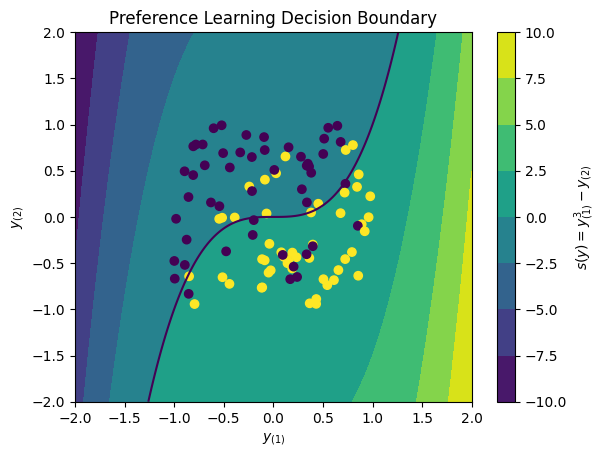

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a dataset of points:
x1, x2, s = generate_pairs(n_pairs=50)

# Create grid
x = np.linspace(-2, 2, 400)
y = np.linspace(-2, 2, 400)
X, Y = np.meshgrid(x, y)

# Define the true reward on the grid
Z = X**3 - Y

# Filled contour plot
plt.figure()
contour = plt.contourf(X, Y, Z)

# Zero-level curve
plt.contour(X, Y, Z, levels=[0])

plt.title("Preference Learning Decision Boundary")
plt.xlabel("$y_{(1)}$")
plt.ylabel("$y_{(2)}$")
plt.colorbar(contour, label="$s(y) = y_{(1)}^3 - y_{(2)}$")

plt.scatter(x1[:, 0], x1[:, 1], c=s)
plt.scatter(x2[:, 0], x2[:, 1], c=1 - s)
plt.show()

**Q4. Design a neural network architecture to learn this decision boundary from pairwise data:**


In [3]:
import torch
import torch.nn as nn

# A small MLP is sufficient for this 2D nonlinear reward function.
class RewardModel(nn.Module):
    """
    Maps a 2D input y to a scalar score s_theta(y).
    """
    def __init__(self, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).squeeze(-1)

## 5. Bradley–Terry Loss and Training


**Q5. Implement the Bradley–Terry loss and plug it into a standard PyTorch training loop:**


In [4]:
from torch.nn import functional as F

def bradley_terry_loss(r1_hat, r2_hat, y):
    """
    Bradley-Terry negative log-likelihood.

    Args:
        r1_hat: [N] predicted scores s_theta(x1)
        r2_hat: [N] predicted scores s_theta(x2)
        y: [N] labels in {0, 1}, where y=1 means x1 is preferred to x2
    """
    logits = r1_hat - r2_hat
    return F.binary_cross_entropy_with_logits(logits, y)

Training Bradley–Terry Model:   0%|          | 0/50 [00:00<?, ?it/s]

Epoch 00 | Loss: 0.5236


Epoch 10 | Loss: 0.0663


Epoch 20 | Loss: 0.0376


Epoch 30 | Loss: 0.0273


Epoch 40 | Loss: 0.0215


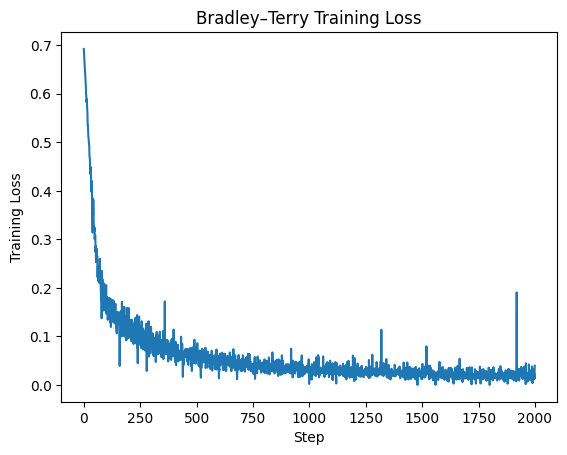

In [5]:
from tqdm.notebook import tqdm

# Hyperparameters
batch_size = 256
epochs = 50
lr = 1e-3

# Data
x1, x2, y = generate_pairs()
dataset = torch.utils.data.TensorDataset(x1, x2, y)
loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Model + optimizer
model = RewardModel()
optimizer = optim.Adam(model.parameters(), lr=lr)

# Training
losses = list()
for epoch in tqdm(range(epochs), desc="Training Bradley–Terry Model"):
    total_loss = 0.0

    for xb1, xb2, yb in loader:
        r1_hat = model(xb1)
        r2_hat = model(xb2)

        loss = bradley_terry_loss(r1_hat, r2_hat, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        losses.append(loss.item())

    if epoch % 10 == 0:
        print(f"Epoch {epoch:02d} | Loss: {total_loss / len(loader):.4f}")

plt.figure()
plt.plot(losses)
plt.xlabel("Step")
plt.ylabel("Training Loss")
plt.title("Bradley–Terry Training Loss")
plt.show()

**Q6. What do you notice about the learned reward function? What has been learned and what cannot be learned?**


**Answer:**

The learned reward model typically recovers the *shape* of the true reward landscape well — contour lines and local ordering of points align with the true function.

What it cannot recover is the *absolute level* of the reward. The Bradley–Terry likelihood depends only on score differences:
$$
\sigma\big(s_\theta(y) - s_\theta(y')\big),
$$
so adding a constant $c$ to every predicted score leaves probabilities unchanged. This means the model can learn relative ordering and geometry, but not the absolute offset of the reward surface.


**Q7 [Extra]. What kinds of preferences does the BT model handle well, and where does it fail?**


**Answer:**

BT works well when preferences are explained by a single latent scalar utility — i.e., preferences are transitive: $a \succ b$ and $b \succ c$ implies $a \succ c$.

BT fails with intransitive or cyclic preferences:
$$
a \succ b, \quad b \succ c, \quad c \succ a.
$$
No single scalar can represent all three simultaneously. The model then assigns similar scores and predicts probabilities near $1/2$.

It also fails when preferences depend on missing context, such as different annotators having systematically different notions of quality.


## 6. Visualizing the Learned vs True Reward


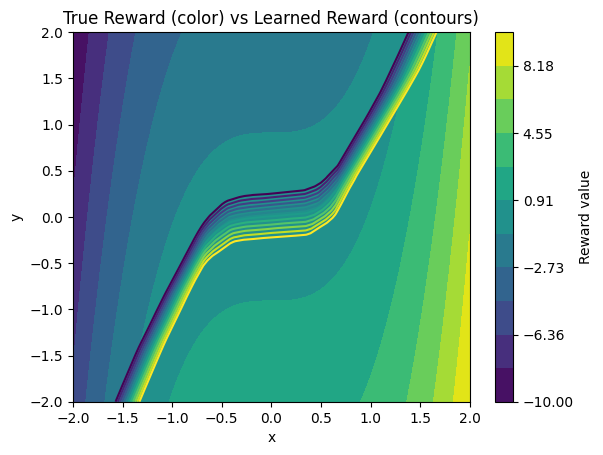

In [6]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Create grid
x = np.linspace(-2, 2, 400)
y = np.linspace(-2, 2, 400)
X, Y = np.meshgrid(x, y)

# True reward
Z_true = X**3 - Y

# Learned reward
grid = torch.from_numpy(
    np.stack([X.ravel(), Y.ravel()], axis=1)
).float()

with torch.no_grad():
    Z_hat = model(grid).numpy().reshape(X.shape)

# Shared contour levels (CRITICAL)
levels = np.linspace(Z_true.min(), Z_true.max(), 12)

# Plot
plt.figure()

# True reward as filled contours
cf = plt.contourf(
    X, Y, Z_true,
    levels=levels
)

# Learned reward as line contours (same levels!)
plt.contour(
    X, Y, Z_hat,
    levels=levels
)

plt.xlabel("x")
plt.ylabel("y")
plt.colorbar(cf, label="Reward value")
plt.title("True Reward (color) vs Learned Reward (contours)")
plt.show()

## 7. Reward Hacking

Even with a well-trained reward model, RL training can go wrong. Two common failure modes, broadly called *reward hacking*, are:

1. **Reward misspecification**: the reward function rewards proxy behaviors that don't correspond to the actual desired behavior (e.g., the CoastRunners game where the agent maximizes score by exploiting the game mechanics rather than finishing the course).

2. **Out-of-distribution failure**: the reward model is accurate in-distribution but generalizes poorly to the distribution the policy shifts toward during training (Langosco et al. 2023).


**Q8. What do these two failure modes look like in the toy 2D setting?**


**Answer:**

For *misspecification*: if we collected labels using a simpler proxy $\tilde{s}(y) = y_{(1)} - y_{(2)}$ instead of the true $s(y) = y_{(1)}^3 - y_{(2)}$, the model faithfully learns the wrong target.

For *out-of-distribution failure*: if we train on $[-1,1]^2$ and evaluate on $[-2,2]^2$, the model may extrapolate badly outside the training region. The reward was accurate in-distribution but fails OOD.


**Q9. What do these failure modes look like in the language setting?**


**Answer:**

For *misspecification*: the reward model may learn spurious shortcuts — rewarding verbosity because longer answers are often preferred, or rewarding sycophancy because agreement is sometimes rated as helpful.

For *out-of-distribution failure*: the reward model generalizes poorly to prompts, styles, or failure modes not well covered in the preference dataset. For example, if all bad answers in training contain obvious offensive words, the model may learn a surface-level detector rather than a genuine notion of helpfulness.


## 8. Measuring In-Distribution vs OOD Correlation


In [7]:
# Look at the correlation of the points in distribution:
with torch.no_grad():

    # Generate new test dataset
    test, _, _ = generate_pairs(n_pairs=100)

    r_true = true_reward(test)
    r_hat = model(test)

    corr = torch.corrcoef(torch.stack([r_true, r_hat]))[0, 1]
    print("Correlation with true reward:", corr.item())


# Generate out-of-distribution test points outside the training range [-1, 1]^2
def generate_bad_data(n_pairs=100):
    return 4 * torch.rand(n_pairs, 2) - 2

with torch.no_grad():

    # Generate new OOD test dataset
    test = generate_bad_data()

    r_true = true_reward(test)
    r_hat = model(test)

    corr = torch.corrcoef(torch.stack([r_true, r_hat]))[0, 1]
    print("Correlation with true reward OOD:", corr.item())

Correlation with true reward: 0.9967254996299744
Correlation with true reward OOD: 0.9336377382278442


## 9. Extension: Full Reward Model on Real Language Data

Steps to build a full language reward model:

1. **Select a preference dataset** from HuggingFace Datasets (e.g., HH-RLHF).
2. **Select a base model** (~1B or 2B parameters). Replace the final layer with a single scalar output head to produce reward scores.
3. **Train with Bradley–Terry loss** using the loop above. Since we cannot plot the true reward, monitor training via: validation loss, pairwise accuracy on a held-out split, and correlation with held-out human ratings.
4. **Evaluate**: test the reward model on self-generated samples or plug it into a full RLHF pipeline.


**Answer:**

This is an open-ended exercise — there is no single standard solution. The key monitoring metrics for training (when the true reward is unknown) are:
- **Validation Bradley–Terry loss** on a held-out preference split
- **Pairwise accuracy**: fraction of held-out pairs ranked correctly
- **Reward correlation** with expert annotations, if available
